# 00. Import Library

In [1]:
import pickle
import time
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.special import softmax
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import SGDClassifier, LogisticRegression
from sklearn.model_selection import StratifiedKFold, GridSearchCV
from sklearn.metrics import accuracy_score, precision_recall_fscore_support, log_loss
from sklearn.metrics import classification_report, ConfusionMatrixDisplay
from sklearn.exceptions import ConvergenceWarning

warnings.filterwarnings('ignore', category=ConvergenceWarning)

# 01. Data preparation

Same CIFAR-10 files as Assignment 04 (`../Assignment04/cifar-10-batches-py`).

In [2]:
BASE = '../Assignment04/cifar-10-batches-py'

batches = [pickle.load(open(f'{BASE}/data_batch_{i}', 'rb'), encoding='bytes') for i in range(1, 6)]
test_batch = pickle.load(open(f'{BASE}/test_batch', 'rb'), encoding='bytes')
CLASSES = [c.decode() for c in pickle.load(open(f'{BASE}/batches.meta', 'rb'), encoding='bytes')[b'label_names']]

# 0~255 -> 0~1
X_train = np.concatenate([b[b'data'] for b in batches]).astype(np.float32) / 255
y_train = np.concatenate([b[b'labels'] for b in batches])
X_test = test_batch[b'data'].astype(np.float32) / 255
y_test = np.array(test_batch[b'labels'])

print('train :', X_train.shape, y_train.shape)
print('test  :', X_test.shape, y_test.shape)

train : (50000, 3072) (50000,)
test  : (10000, 3072) (10000,)


# 02_1. SVM (hinge) loss

$L_i = \sum_{j \neq y_i} \max(0, s_j - s_{y_i} + 1)$

Checked with the 3-image example of the lecture (Week 7-2, cat / car / frog).

In [3]:
# rows : cat, car, frog image / columns : cat, car, frog score
scores = np.array([[3.2, 5.1, -1.7], [1.3, 4.9, 2.0], [2.2, 2.5, -3.1]])
y = np.array([0, 1, 2])

margins = np.maximum(0, scores - scores[[0, 1, 2], y][:, None] + 1)
margins[[0, 1, 2], y] = 0   # j = y_i 는 제외
print('L_i :', margins.sum(axis=1).round(2))
print('L :', margins.sum(axis=1).mean().round(2))

L_i : [ 2.9  0.  12.9]
L : 5.27


# 02_2. Softmax function & softmax loss

$P(Y = k \mid X = x_i) = \frac{e^{s_k}}{\sum_j e^{s_j}}$, $\quad L_i = -\log P(Y = y_i \mid X = x_i)$

In [4]:
P = softmax(scores, axis=1)   # exp -> normalize
print('P of image 1 :', P[0].round(2))
print('L_i :', -np.log(P[[0, 1, 2], y]).round(4))
print('L :', round(log_loss(y, P), 4))

P of image 1 : [0.13 0.87 0.  ]
L_i : [2.0404 0.0791 6.1565]
L : 2.7587


# 03. Linear classifier & 5-fold cross-validation

Both are linear classifiers $f(x, W) = Wx + b$ ($W$ : 10 x 3072, $b$ : 10). Only the loss is different.

- SVM : `SGDClassifier(loss='hinge')`, stochastic gradient descent for 10 epochs (sklearn trains the 10 classes one-vs-rest)
- Softmax : `LogisticRegression`, softmax + cross-entropy loss, lbfgs for 100 iterations

`StandardScaler` is inside the pipeline, so each fold is scaled with its own train part only.
The regularization strength (`alpha` for SGD, `C` = 1 / strength for LogisticRegression) is chosen by `GridSearchCV` on the same 5 folds as Assignment 04,
and the best setting is then retrained on all 50,000 train images.

In [5]:
skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=0)
scoring = {'Accuracy': 'accuracy', 'Precision': 'precision_macro', 'Recall': 'recall_macro', 'F1': 'f1_macro'}

models = {
    'SVM': GridSearchCV(make_pipeline(StandardScaler(), SGDClassifier(loss='hinge', max_iter=10, tol=None, random_state=0, n_jobs=-1)),
                        {'sgdclassifier__alpha': [1e-4, 1e-3, 1e-2, 1e-1]}, cv=skf, scoring=scoring, refit='Accuracy'),
    'Softmax': GridSearchCV(make_pipeline(StandardScaler(), LogisticRegression(max_iter=100)),
                            {'logisticregression__C': [1e-4, 1e-3, 1e-2, 1e-1]}, cv=skf, scoring=scoring, refit='Accuracy'),
}

for name, model in models.items():
    start = time.time()
    model.fit(X_train, y_train)
    print(f'{name} done ({time.time() - start:.0f} s)')

SVM done (143 s)


Softmax done (783 s)


# 03_1. Effect of regularization

Mean and std over the 5 folds.

In [6]:
cols = ['mean_test_Accuracy', 'std_test_Accuracy', 'mean_test_Precision', 'mean_test_Recall', 'mean_test_F1', 'mean_fit_time']
pd.DataFrame(models['SVM'].cv_results_).set_index('param_sgdclassifier__alpha')[cols].round(4)

,mean_test_Accuracy,std_test_Accuracy,mean_test_Precision,mean_test_Recall,mean_test_F1,mean_fit_time
param_sgdclassifier__alpha,,,,,,
0.0001,0.3849,0.0062,0.3966,0.3849,0.3877,6.7911
0.0010,0.3887,0.0048,0.3898,0.3887,0.3878,6.5251
0.0100,0.3820,0.0044,0.3837,0.3820,0.3797,6.5102
0.1000,0.3758,0.0057,0.3834,0.3758,0.3719,6.5692


In [7]:
pd.DataFrame(models['Softmax'].cv_results_).set_index('param_logisticregression__C')[cols].round(4)

,mean_test_Accuracy,std_test_Accuracy,mean_test_Precision,mean_test_Recall,mean_test_F1,mean_fit_time
param_logisticregression__C,,,,,,
0.0001,0.4075,0.0049,0.4028,0.4075,0.4031,35.1873
0.0010,0.4134,0.0048,0.4093,0.4134,0.4102,36.5057
0.0100,0.3987,0.0050,0.3965,0.3987,0.3971,39.1474
0.1000,0.3944,0.0046,0.3930,0.3944,0.3934,35.6004


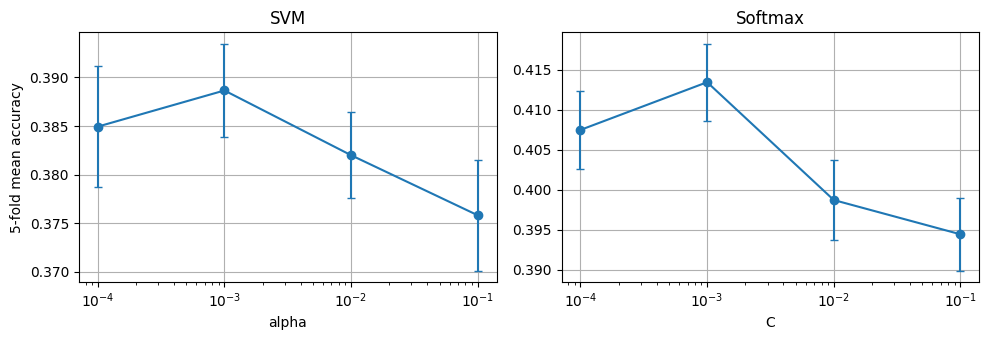

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(10, 3.5))
for ax, (name, param) in zip(axes, [('SVM', 'alpha'), ('Softmax', 'C')]):
    res = pd.DataFrame(models[name].cv_results_)
    ax.errorbar(res.filter(like='param_').iloc[:, 0].astype(float), res['mean_test_Accuracy'], yerr=res['std_test_Accuracy'], marker='o', capsize=3)
    ax.set_xscale('log')
    ax.set_xlabel(param)
    ax.set_title(name)
    ax.grid(True)
axes[0].set_ylabel('5-fold mean accuracy')
plt.tight_layout()
plt.show()

In [9]:
for name, model in models.items():
    print(f'{name} : best {model.best_params_}, 5-fold accuracy = {model.best_score_:.4f}')

best = 'Softmax' if models['Softmax'].best_score_ > models['SVM'].best_score_ else 'SVM'
print('\nBest model (5-fold) :', best)

SVM : best {'sgdclassifier__alpha': 0.001}, 5-fold accuracy = 0.3887
Softmax : best {'logisticregression__C': 0.001}, 5-fold accuracy = 0.4134

Best model (5-fold) : Softmax


# 04_1. Final evaluation on the test set

Best setting of each model (already retrained on all 50,000 train images) on the 10,000 images of `test_batch`.

In [10]:
results, test_pred = [], {}
for name, model in models.items():
    start = time.time()
    test_pred[name] = model.predict(X_test)
    test_time = time.time() - start
    p, r, f, _ = precision_recall_fscore_support(y_test, test_pred[name], average='macro')
    results.append({'model': name, 'best param': list(model.best_params_.values())[0], 'Accuracy': accuracy_score(y_test, test_pred[name]),
                    'Precision': p, 'Recall': r, 'F1': f, 'train time (s)': model.refit_time_, 'test time (s)': test_time})

pd.DataFrame(results).round(4)

,model,best param,Accuracy,Precision,Recall,F1,train time (s),test time (s)
0,SVM,0.001,0.3942,0.3980,0.3942,0.3945,8.0858,0.5174
1,Softmax,0.001,0.4177,0.4139,0.4177,0.4147,42.8085,0.2044


`predict_proba` of `LogisticRegression` is the softmax of its 10 scores $Wx + b$ :

In [11]:
clf = models['Softmax'].best_estimator_
s = clf.decision_function(X_test[:5])   # Wx + b
print(np.allclose(softmax(s, axis=1), clf.predict_proba(X_test[:5])))
print(f'P of test image 0 ({CLASSES[y_test[0]]}) :', softmax(s, axis=1)[0].round(3))

True
P of test image 0 (cat) : [0.014 0.033 0.083 0.394 0.021 0.106 0.225 0.003 0.12  0.001]


# 04_2. Per-class results

In [12]:
pred = test_pred[best]
print(f'[{best}] test set\n')
print(classification_report(y_test, pred, target_names=CLASSES, digits=4))

[Softmax] test set

              precision    recall  f1-score   support

    airplane     0.4615    0.4980    0.4791      1000
  automobile     0.4747    0.4880    0.4813      1000
        bird     0.3421    0.2990    0.3191      1000
         cat     0.2873    0.2660    0.2762      1000
        deer     0.3786    0.3040    0.3372      1000
         dog     0.3518    0.3550    0.3534      1000
        frog     0.4161    0.4910    0.4505      1000
       horse     0.4769    0.4550    0.4657      1000
        ship     0.5018    0.5460    0.5230      1000
       truck     0.4485    0.4750    0.4614      1000

    accuracy                         0.4177     10000
   macro avg     0.4139    0.4177    0.4147     10000
weighted avg     0.4139    0.4177    0.4147     10000



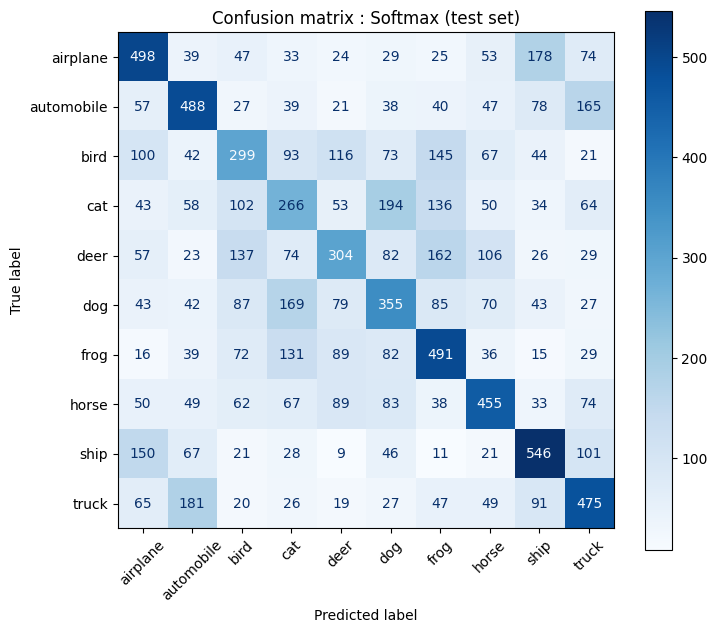

In [13]:
fig, ax = plt.subplots(figsize=(8, 7))
ConfusionMatrixDisplay.from_predictions(y_test, pred, display_labels=CLASSES, xticks_rotation=45, cmap='Blues', ax=ax)
plt.title(f'Confusion matrix : {best} (test set)')
plt.show()

# 04_3. Learned weights as templates

Each row of $W$ reshaped back to 32 x 32 x 3 (visual viewpoint, Week 7-2), min-max scaled for display.

SVM : W (10, 3072) , b (10,)


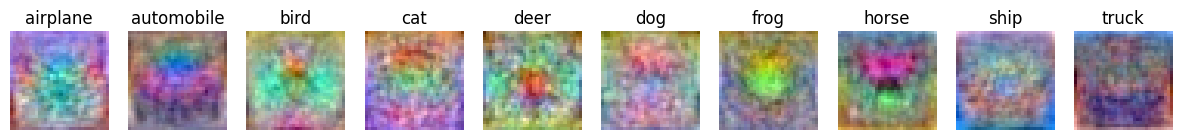

Softmax : W (10, 3072) , b (10,)


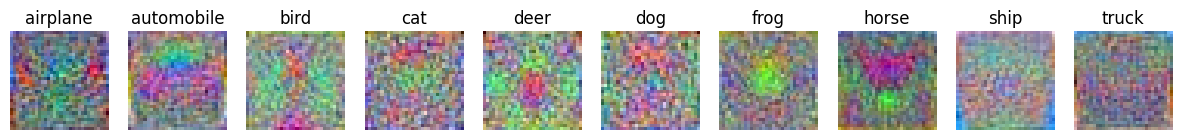

In [14]:
for name, model in models.items():
    W = model.best_estimator_[-1].coef_
    print(name, ': W', W.shape, ', b', model.best_estimator_[-1].intercept_.shape)
    plt.figure(figsize=(15, 2))
    for c in range(10):
        w = W[c].reshape(3, 32, 32).transpose(1, 2, 0)
        plt.subplot(1, 10, c + 1)
        plt.imshow((w - w.min()) / (w.max() - w.min()))
        plt.title(CLASSES[c])
        plt.axis('off')
    plt.show()

# 05. Comparison

| Model | Best setting (5-fold) | 5-fold Accuracy | Test Accuracy | Test Precision | Test Recall | Test F1 | Test time |
|---|---|---|---|---|---|---|---|
| Softmax | C = 0.001 | 0.4134 ± 0.0048 | 0.4177 | 0.4139 | 0.4177 | 0.4147 | 0.20 s |
| SVM | alpha = 0.001 | 0.3887 ± 0.0048 | 0.3942 | 0.3980 | 0.3942 | 0.3945 | 0.52 s |
| KNN L1 (Assignment 04) | k = 5 | 0.3791 ± 0.0030 | 0.3921 | 0.4560 | 0.3921 | 0.3890 | 302 s |

- Best model is Softmax with C = 0.001, chosen by 5-fold CV only. Test accuracy is 41.8%, close to the 5-fold 41.3%.
- The loss values are the same as the lecture example (SVM L = 5.27, softmax 0.13 / 0.87 / 0.00). Image 2 already meets the margin, so its SVM loss is 0, but its softmax loss is still 0.079.
- Regularization : both too weak and too strong lower the accuracy. 0.001 was the best for both models (`alpha` for SVM, `C` for softmax).
- Softmax is about 2.5 points better than SVM. One reason may be that sklearn trains the SVM as 10 separate one-vs-rest classifiers, while softmax learns the 10 classes together.
- vs KNN : the accuracy is a bit higher (41.8% vs 39.2%) and the test set takes 0.2 s instead of 302 s, because only $W$ (10 x 3072) and $b$ (10) are kept instead of all 50,000 train images.
- Limit : one template per class, so the model mostly learns color and position. Most errors are between classes that look alike : cat -> dog 194, truck -> automobile 181, airplane -> ship 178, dog -> cat 169.